<a href="https://colab.research.google.com/github/Harshitha-3-prog/Deep-learning-CCA/blob/main/2_keras_unet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 2. TensorFlow/Keras – U-Net for textile defect segmentation
Runtime: **CPU** – same runtime type as the PyTorch notebook. Run all cells in order. Keep the browser tab open during training.

In [2]:
# ---- Shared configuration (keep IDENTICAL in both framework notebooks) ----
import os, time, json, sys, platform
import numpy as np, psutil
SEED, BATCH, EPOCHS, LR, NCLS = 42, 8, 20, 1e-3, 5
DRIVE = "/content/drive/MyDrive/CCA2"
DATA  = f"{DRIVE}/fabric_256.npz"
from google.colab import drive
drive.mount("/content/drive")

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| backend:", keras.backend.backend(), "| GPUs:", tf.config.list_physical_devices("GPU"))
d = np.load(DATA)
Xtr, Ytr, Xva, Yva, Xte, Yte = [d[k] for k in ["X_train","Y_train","X_val","Y_val","X_test","Y_test"]]
print(Xtr.shape, Xva.shape, Xte.shape, list(d["class_names"]))
def make_ds(X, Y, shuffle):
    ds = tf.data.Dataset.from_tensor_slices((X, Y))
    if shuffle: ds = ds.shuffle(len(X), seed=SEED)
    ds = ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32) / 255., tf.cast(y, tf.int32)))
    return ds.prefetch(1)
train_ds, val_ds, test_ds = make_ds(Xtr,Ytr,True), make_ds(Xva,Yva,False), make_ds(Xte,Yte,False)
train_eval_ds = make_ds(Xtr,Ytr,False)

Mounted at /content/drive
TensorFlow 2.21.0 | Keras 3.13.2 | backend: tensorflow | GPUs: []
(1685, 256, 256, 3) (364, 256, 256, 3) (358, 256, 256, 3) [np.str_('background'), np.str_('Needle Mark'), np.str_('Hole'), np.str_('Missing Yarn'), np.str_('Stains')]


In [3]:
# ---- Shared metric code (identical in both notebooks) ----
def conf_matrix(y_true, y_pred, n=NCLS):
    return np.bincount((y_true.astype(np.int64) * n + y_pred).ravel(),
                       minlength=n * n).reshape(n, n)

def summarize(conf):
    acc = np.trace(conf) / conf.sum()                 # pixel accuracy
    inter = np.diag(conf)
    union = conf.sum(0) + conf.sum(1) - inter
    iou = np.where(union > 0, inter / np.maximum(union, 1), np.nan)
    return acc, iou                                    # iou[0] = background

In [4]:
# ---- Model (this is the code to show in report Section 3.3) ----
def block(x, f):
    x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
    return layers.Conv2D(f, 3, padding="same", activation="relu")(x)
inp = keras.Input((256, 256, 3))
x1 = block(inp, 16)
x2 = block(layers.MaxPooling2D()(x1), 32)
x3 = block(layers.MaxPooling2D()(x2), 64)
u2 = layers.Conv2DTranspose(32, 2, strides=2)(x3)
d2 = block(layers.Concatenate()([u2, x2]), 32)
u1 = layers.Conv2DTranspose(16, 2, strides=2)(d2)
d1 = block(layers.Concatenate()([u1, x1]), 16)
out = layers.Conv2D(NCLS, 1, activation="softmax")(d1)   # (N,256,256,5)
model = keras.Model(inp, out)
model.compile(optimizer=keras.optimizers.Adam(LR),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
n_params = model.count_params(); print("Parameters:", n_params)

Parameters: 117109


In [5]:
proc = psutil.Process()
class Log(keras.callbacks.Callback):          # epoch time (includes validation, as in the PyTorch loop) + memory
    def on_train_begin(self, logs=None): self.times, self.rss = [], []
    def on_epoch_begin(self, epoch, logs=None): self.t0 = time.time()
    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.time() - self.t0); self.rss.append(proc.memory_info().rss / 1e6)
log = Log()
t_all = time.time()
hist = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=[log], verbose=2)
total_time = time.time() - t_all

Epoch 1/20
211/211 - 852s - 4s/step - accuracy: 0.9720 - loss: 0.2144 - val_accuracy: 0.9795 - val_loss: 0.1302
Epoch 2/20
211/211 - 824s - 4s/step - accuracy: 0.9796 - loss: 0.1237 - val_accuracy: 0.9795 - val_loss: 0.1290
Epoch 3/20
211/211 - 829s - 4s/step - accuracy: 0.9796 - loss: 0.1233 - val_accuracy: 0.9795 - val_loss: 0.1244
Epoch 4/20
211/211 - 790s - 4s/step - accuracy: 0.9796 - loss: 0.1207 - val_accuracy: 0.9795 - val_loss: 0.1236
Epoch 5/20
211/211 - 851s - 4s/step - accuracy: 0.9796 - loss: 0.1206 - val_accuracy: 0.9795 - val_loss: 0.1254
Epoch 6/20
211/211 - 802s - 4s/step - accuracy: 0.9796 - loss: 0.1203 - val_accuracy: 0.9795 - val_loss: 0.1279
Epoch 7/20
211/211 - 843s - 4s/step - accuracy: 0.9796 - loss: 0.1202 - val_accuracy: 0.9795 - val_loss: 0.1220
Epoch 8/20
211/211 - 786s - 4s/step - accuracy: 0.9796 - loss: 0.1196 - val_accuracy: 0.9795 - val_loss: 0.1225
Epoch 9/20
211/211 - 833s - 4s/step - accuracy: 0.9796 - loss: 0.1186 - val_accuracy: 0.9795 - val_loss:

In [6]:
def evaluate(ds):
    conf = np.zeros((NCLS, NCLS), dtype=np.int64)
    for xb, yb in ds:
        conf += conf_matrix(yb.numpy(), model(xb, training=False).numpy().argmax(-1))
    return conf
c_tr, c_va, c_te = evaluate(train_eval_ds), evaluate(val_ds), evaluate(test_ds)
(acc_tr, _), (acc_va, _), (acc_te, iou_te) = summarize(c_tr), summarize(c_va), summarize(c_te)
te_loss = model.evaluate(test_ds, verbose=0)[0]
# inference time: one image at a time, after one warm-up call
xs = (Xte[:50].astype("float32") / 255.)
model(xs[:1], training=False); t = time.time()
for i in range(50): model(xs[i:i+1], training=False)
inf_ms = (time.time() - t) / 50 * 1000

H = {"train_loss": hist.history["loss"], "val_loss": hist.history["val_loss"],
     "epoch_time": log.times, "rss_mb": log.rss}
R = {"framework": f"TensorFlow {tf.__version__} / Keras {keras.__version__}", "epochs": EPOCHS, "params": n_params,
     "train_acc": acc_tr, "val_acc": acc_va, "test_acc": acc_te,
     "final_train_loss": H["train_loss"][-1], "final_val_loss": H["val_loss"][-1], "test_loss": te_loss,
     "test_mIoU_defects": float(np.nanmean(iou_te[1:])), "test_IoU_per_class": [None if np.isnan(v) else float(v) for v in iou_te],
     "total_train_time_s": total_time, "mean_epoch_time_s": float(np.mean(log.times)),
     "inference_ms_per_image": inf_ms, "peak_rss_mb": max(log.rss), "history": H}
json.dump(R, open(f"{DRIVE}/results_keras.json", "w"), indent=1)
print("=== COPY THIS BLOCK ===")
for k, v in R.items():
    if k != "history": print(f"{k}: {v}")

=== COPY THIS BLOCK ===
framework: TensorFlow 2.21.0 / Keras 3.13.2
epochs: 20
params: 117109
train_acc: 0.9796379293107845
val_acc: 0.9794833005129636
test_acc: 0.9815854972967223
final_train_loss: 0.11239204555749893
final_val_loss: 0.11493535339832306
test_loss: 0.10587335377931595
test_mIoU_defects: 0.0
test_IoU_per_class: [0.9815854972967223, 0.0, 0.0, 0.0, 0.0]
total_train_time_s: 16198.394444465637
mean_epoch_time_s: 809.9121798038483
inference_ms_per_image: 166.83759212493896
peak_rss_mb: 3512.172544


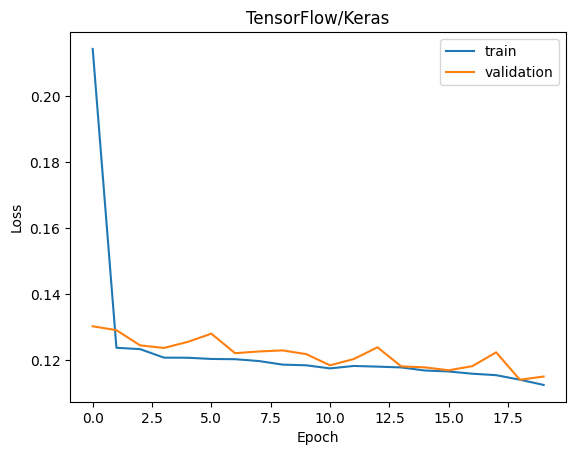

In [7]:
import matplotlib.pyplot as plt
plt.plot(H["train_loss"], label="train"); plt.plot(H["val_loss"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("TensorFlow/Keras"); plt.legend()
plt.savefig(f"{DRIVE}/keras_curves.png", dpi=150, bbox_inches="tight"); plt.show()